# Group Homework 3 · The GoMart report makeover
**Data Visualization · UEH · Session 3** · team notebook

| | |
|---|---|
| **Team** | *team name* · **team number** (from the LMS list): __ |
| **Status** | Formative: written feedback with the rubric in the brief. Task 0 is the first version of Module M3 of your project |
| **Submit** | File ▸ Download ▸ .ipynb as `GH3_TeamName.ipynb` + the evidence folder of Task 4, within 7 days on the LMS |

Read the brief *Group Homework 3* first. All GoMart data is simulated.

## Task 5 · One-page summary for the operations director (write this last)
**Big Idea:** *one complete sentence.*

*At most 100 words. The one-page figure is made in the last code cell of the notebook (it needs everything above);
after "Restart and run all", paste its image here.*

## Task 0 · Project: house style v0 and makeover plan (Module M3)
**Allocated project:** P__ · *title*

1. Put your `house_style.py` v0 in the cell below (palette in fixed order, sequential map, diverging map, fonts, number format).
2. Show the evidence: a swatch of your palette in colour, in greyscale and with simulated deuteranopia.
3. Makeover plan for one published chart from your domain: link, screenshot, critique table, photo of your hand sketch.

In [ ]:
# Task 0 · house_style.py v0 for your project (paste the file content here, then run it)
# PROJECT_PALETTE = [...]       # fixed order, one colour per category of your project
# SEQ_CMAP = "..."; DIV_CMAP = "..."
# def use_house_style(): ...

In [ ]:
# Task 0 · evidence: palette swatch in colour, greyscale, deuteranopia
# (use fig_to_rgb, to_grey and simulate_cvd from the Setup section below)

**Makeover plan.** Source (link, date accessed): ...

| # | What I see | Principle broken (name it) | Effect on the reader | My fix |
|---|---|---|---|---|
| 1 | | | | |
| 2 | | | | |
| 3 | | | | |
| 4 | | | | |

*Insert the photo of your hand sketch here.*

## Setup
Upload `gomart_orders_2025_clean.csv`, `gomart_districts.csv` and `gomart_targets_2025.csv`.
Run `gomart_bad_report.py` once (or open `gomart_bad_report.pdf`) to see the six charts you will audit.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import TwoSlopeNorm, to_rgb

GREY, LIGHT, DARK, BLUE, ORANGE = "#a3a29c", "#d9d8d3", "#52514e", "#2a78d6", "#eb6834"
ZONE_COLOR = {"Central": "#a9c9ef", "Inner": "#5b9be3", "Outer": "#1f4f8f"}   # ordered: light -> dark

In [2]:
from pathlib import Path
DATA = Path("../../data/raw")                    # inside our repository
if not (DATA / "gomart_orders_2025_clean.csv").exists():
    DATA = Path(".")                             # files uploaded next to the notebook (Colab, LMS)
orders = pd.read_csv(DATA / "gomart_orders_2025_clean.csv", parse_dates=["order_time"])
districts = pd.read_csv(DATA / "gomart_districts.csv")
targets = pd.read_csv(DATA / "gomart_targets_2025.csv")
orders = orders.merge(districts, on="district", how="left", validate="many_to_one")
orders["month"] = orders["order_time"].dt.strftime("%Y-%m")
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
orders["weekday"] = pd.Categorical(orders["order_time"].dt.strftime("%a"), categories=days, ordered=True)
orders["hour"] = orders["order_time"].dt.hour
tiers = ["none", "Silver", "Gold", "Platinum"]
orders["member_tier"] = pd.Categorical(orders["member_tier"], categories=tiers, ordered=True)
delivered = orders[orders["status"] == "delivered"]
print(orders.shape, "| orders without zone:", orders["zone"].isna().sum())

(5913, 16) | orders without zone: 0


Helper functions from Tutorial 3 (given):

In [3]:
def fig_to_rgb(fig):
    fig.canvas.draw()
    return np.asarray(fig.canvas.buffer_rgba())[..., :3] / 255

def to_grey(rgb):
    return np.asarray(rgb)[..., :3] @ np.array([0.299, 0.587, 0.114])

DEUTAN = np.array([[0.367322, 0.860646, -0.227968], [0.280085, 0.672501, 0.047413],
                   [-0.011820, 0.042940, 0.968881]])

def simulate_cvd(rgb, M=DEUTAN):
    lin = np.where(rgb <= 0.04045, rgb / 12.92, ((rgb + 0.055) / 1.055) ** 2.4)
    sim = np.clip(lin @ M.T, 0, 1)
    return np.where(sim <= 0.0031308, 12.92 * sim, 1.055 * sim ** (1 / 2.4) - 0.055)

## Task 1 · Audit the report
For each of the six charts: the task the chart should support (action + target), then at least four problems.

| Chart | Task it should support | Problem | Principle (name it) | Effect on the reader |
|---|---|---|---|---|
| 1 Orders by district | | | | |
| 1 | | | | |
| 2 Payments | | | | |
| ... | | | | |

## Task 2 · Redesign
### Chart 1 · Orders by district
*Task:* ...  *Why this chart:* ...

In [ ]:
# TODO: write your code here

In [ ]:
# TODO: write your code here

### Chart 2 · Payments
*Task:* ...  *Why this chart:* ...

In [ ]:
# TODO: write your code here

### Chart 3 · Delivery time
*Task:* identify where deliveries are slow, and compare each district's delivery time with its distance to the hub.  
*Why this chart:* horizontal bars sorted by time put the slowest district on top and start at zero, so each bar's length is honest; the distance in each label answers the second half of the task without a second chart.

*Summary:* the median of delivered orders (cancelled orders have no delivery time). The mean gives the same ranking and differs by less than half a minute (output below), so the choice does not change the finding; the median describes the typical order.  
*Colour:* grey for every district, blue only for the districts slower than the city median.

In [4]:
# Chart 3 · the numbers in the title and subtitle, checked here
d3 = (delivered.groupby("district")
               .agg(minutes=("delivery_min", "median"), mean=("delivery_min", "mean"),
                    km=("km_to_hub", "first"))
               .sort_values("minutes"))
city = delivered["delivery_min"].median()
slow = d3["minutes"] > city                                   # blue: slower than the city median
per_km = delivered["delivery_min"].cov(delivered["km_to_hub"]) / delivered["km_to_hub"].var()
top, base = d3.index[-1], d3.index[0]

print(d3.round(1).to_string(), "\n")
print("delivered orders without a delivery time:", delivered["delivery_min"].isna().sum())
print(f"largest gap between mean and median: {(d3['mean'] - d3['minutes']).abs().max():.2f} min;",
      "same ranking:", list(d3.sort_values("mean").index) == list(d3.index))
print(f"city median: {city:.1f} min")
print(f"{top} / {base}: {d3.loc[top, 'minutes']:.1f} / {d3.loc[base, 'minutes']:.1f} = "
      f"{d3.loc[top, 'minutes'] / d3.loc[base, 'minutes']:.2f}")
print(f"minutes per extra km: {per_km:.2f}")
print("blue districts = the four farthest from the hub:",
      set(d3.index[slow]) == set(d3["km"].nlargest(4).index))

              minutes  mean    km
district                         
District 1       26.7  26.7   2.1
District 3       29.3  29.1   2.8
District 10      30.7  30.7   3.5
Phu Nhuan        32.2  32.2   4.0
Binh Thanh       33.7  33.6   4.6
Tan Binh         34.9  35.2   5.2
District 7       41.2  41.2   7.5
Go Vap           42.1  41.9   7.9
Binh Tan         49.7  49.6  10.8
Thu Duc City     51.7  51.7  11.5 

delivered orders without a delivery time: 6
largest gap between mean and median: 0.26 min; same ranking: True
city median: 36.3 min
Thu Duc City / District 1: 51.7 / 26.7 = 1.94
minutes per extra km: 2.61
blue districts = the four farthest from the hub: True


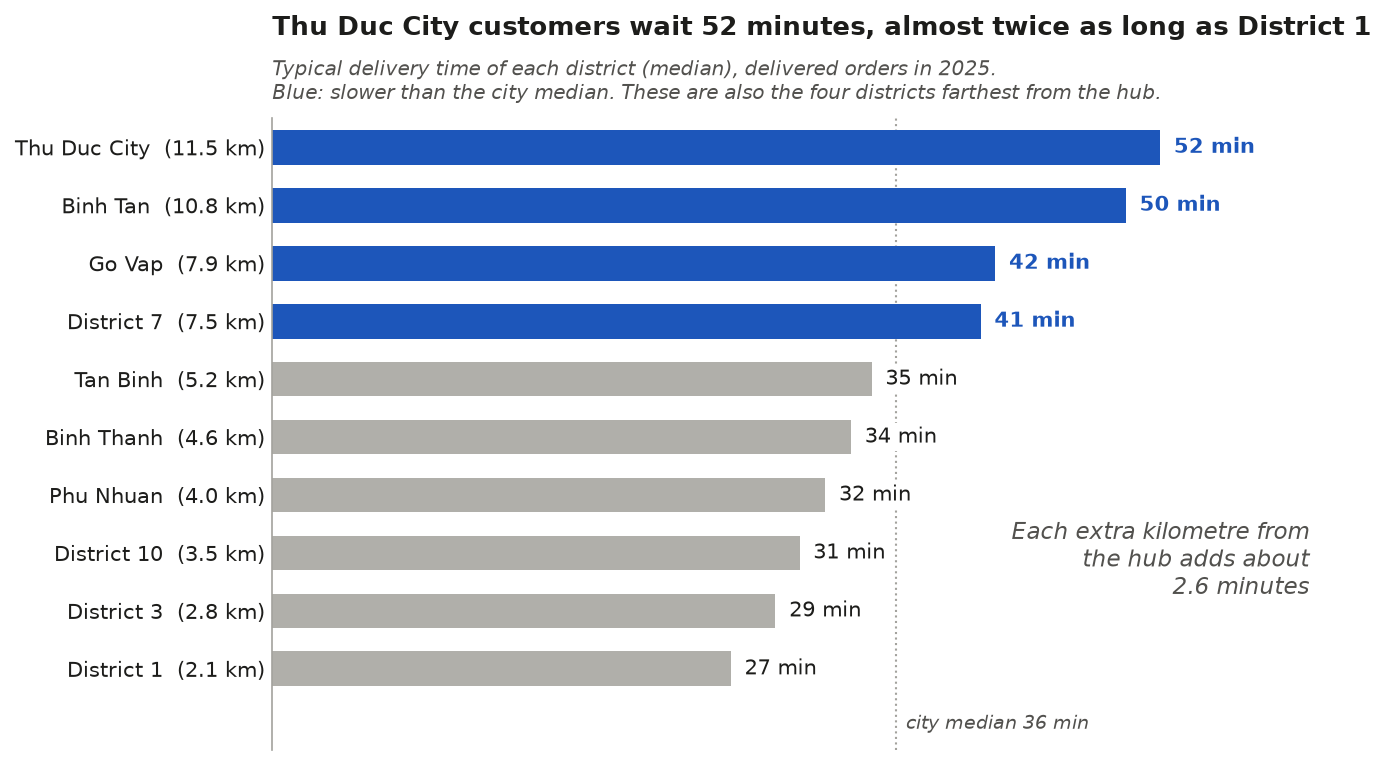

In [5]:
# Chart 3 · redesign: slowest district on top, blue only where delivery is slower than the city median
INK, NOTE, AXIS = "#1d1d1b", "#52514e", "#a3a29d"              # same greys as our GH2 charts
BAR, HIGHLIGHT = "#b0afaa", "#1d56ba"

fig3, ax = plt.subplots(figsize=(9, 5.2), dpi=150)
names = [f"{d}  ({km:.1f} km)" for d, km in zip(d3.index, d3["km"])]
bars = ax.barh(names, d3["minutes"], height=0.6, color=np.where(slow, HIGHLIGHT, BAR))
for bar, minutes, is_slow in zip(bars, d3["minutes"], slow):
    ax.text(bar.get_width() + 0.8, bar.get_y() + bar.get_height() / 2, f"{minutes:.0f} min", va="center",
            fontsize=10, fontweight="bold" if is_slow else "normal", color=HIGHLIGHT if is_slow else INK,
            bbox=dict(facecolor="white", edgecolor="none", pad=1.5))  # readable over the median line
ax.axvline(city, color=AXIS, lw=1, ls=":", zorder=0)
ax.text(city + 0.6, -0.95, f"city median {city:.0f} min", fontsize=9, style="italic", color=NOTE, va="center")
ax.text(0.99, 0.30, f"Each extra kilometre from\nthe hub adds about\n{per_km:.1f} minutes",
        transform=ax.transAxes, ha="right", va="center", fontsize=11, style="italic", color=NOTE)

ax.set_xlim(0, d3["minutes"].max() * 1.18)                     # bars start at zero
ax.set_ylim(-1.4, len(d3) - 0.5)                               # room under the bars for the median label
ax.set_xticks([])                                              # every bar carries its own number
ax.tick_params(axis="y", length=0, labelsize=10, labelcolor=INK)
ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.spines["left"].set_color(AXIS)
ax.set_title(f"{top} customers wait {d3.loc[top, 'minutes']:.0f} minutes, almost twice as long as {base}",
             loc="left", fontsize=12.5, fontweight="bold", color=INK, pad=40)
ax.text(0, 1.02, "Typical delivery time of each district (median), delivered orders in 2025.\n"
        "Blue: slower than the city median. These are also the four districts farthest from the hub.",
        transform=ax.transAxes, fontsize=9.5, style="italic", color=NOTE, va="bottom")
fig3.tight_layout()
plt.show()

### Chart 4 · Peak times
*Task:* ...  *Why this chart:* ...

In [ ]:
# TODO: write your code here

### Chart 5 · Targets
*Task:* ...  *Why this chart:* ...

In [ ]:
# TODO: write your code here

In [ ]:
# TODO: write your code here

### Chart 6 · Basket by tier
*Task:* ...  *Why this chart:* ...

In [ ]:
# TODO: write your code here

In [ ]:
# TODO: write your code here

*Check: every number in your six titles, with the output that proves it.*

## Task 3 · Test for every reader
Greyscale and deuteranopia versions of all six redesigns. Then: one change you made because of a test.

In [ ]:
# TODO: write your code here

*The change we made because of a test, and why:*

## Task 4 · Perception experiment
### 4.1 Your stimulus sheet
Use **your team number** from the LMS list. Print the sheet (or put it in a form). Do not show the true values to anyone.

In [ ]:
def make_stimuli(team_number, path="stimulus_sheet.png"):
    """Perception experiment: one sheet with three panels (bars, pie, bubbles).
    Each panel shows five values A-E; the largest is marked with *. Values differ per panel
    and per team, so every team has its own experiment. Returns the true values (keep them secret)."""
    rng = np.random.default_rng(1000 + team_number)
    truth = {}
    fig, axs = plt.subplots(1, 3, figsize=(13, 4.2))
    for ax, kind in zip(axs, ["bars", "pie", "bubbles"]):
        v = np.round(rng.uniform(10, 90, 5))
        v[rng.integers(5)] = 100                                  # the reference value (only one)
        labels = [L + ("*" if val == 100 else "") for L, val in zip("ABCDE", v)]
        truth[kind] = dict(zip("ABCDE", v.astype(int).tolist()))
        if kind == "bars":
            ax.bar(labels, v, color="white", edgecolor="black")
            ax.set_yticks([]); ax.spines[["top", "right", "left"]].set_visible(False)
        elif kind == "pie":
            ax.pie(v, labels=labels, colors=["white"] * 5, wedgeprops=dict(edgecolor="black"),
                   startangle=90, counterclock=False)
        else:
            ax.scatter(range(5), [0] * 5, s=v / 100 * 2500, color="white", edgecolor="black")
            for i, L in enumerate(labels):
                ax.text(i, -0.55, L, ha="center")
            ax.set_ylim(-0.8, 0.8); ax.set_xlim(-0.7, 4.7); ax.axis("off")
        ax.set_title(f"Panel {['bars', 'pie', 'bubbles'].index(kind) + 1}")
    fig.text(0.5, 0.0, "The value marked * is 100. Estimate the other four values in each panel. "
             "Do not measure; answer within 30 seconds per panel.", ha="center", fontsize=10)
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.close(fig)
    return truth

In [ ]:
# truth = make_stimuli(team_number=__)
# print(truth)
# TODO: write your code here

### 4.2 Protocol (fill in before you collect)
Who (≥ 15 people not in this course), where, when, how you avoid helping them, how you record answers, consent, no names.

### 4.3 Your answers
Save your answers as `experiment_answers.csv` with the columns
`respondent, encoding, item, true, judged, collector` (one row per estimate; `collector` = the student ID of the team
member who collected it). Upload it next to the notebook.

In [ ]:
# answers = pd.read_csv("experiment_answers.csv")
# answers["log_error"] = np.log2(np.abs(answers["judged"] - answers["true"]) + 1 / 8)   # Cleveland & McGill (1984)
# print(answers.groupby("encoding")["log_error"].agg(["mean", "count"]).round(2))

In [ ]:
# Task 4.3: compute log_error for your own answers and summarise it by encoding
# TODO: write your code here

### 4.4 Result chart

In [ ]:
# TODO: write your code here

### 4.5 Interpretation (at most 150 words)
Does your result agree with Cleveland & McGill (1984)? Which item was hardest, and why? Two limitations of your experiment.

## Task 5 · The one-page figure
Three panels, one action title, consistent colours with Tasks 2-3.

In [ ]:
# Task 5: one figure, three panels, one action title
# TODO: write your code here

## Task 6 · Team and AI
| Member | What they did | Answers collected (Task 4) | Share of work |
|---|---|---|---|
| | | | |

In [ ]:
AI_USE = """
Tool(s) used:
What we asked:
What we checked or changed ourselves:
"""
print(AI_USE)